# Multi-Node Self-Loop Tests


In [ ]:
import sys, os, numpy as np, matplotlib.pyplot as plt

# Environment detection: Colab vs local
in_colab = False
try:
    import google.colab
    in_colab = True
except ImportError:
    pass

if in_colab:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = '/content/drive/MyDrive/ColabProject/utils'
else:
    utils_path = os.path.join(os.getcwd(), "..", "utils")

sys.path.insert(0, utils_path)

exp_dir = os.path.join(os.path.dirname(utils_path), "experiments")
os.makedirs(exp_dir, exist_ok=True)

from test_networks import *
from self_loop_utils import *
from loop_topology_utils import *
from laplacian_utils import print_laplacian
from pipeline_utils import run_full_pipeline, run_impedance
from network_visualization import draw_chain_panel, draw_ladder_panel
from network_visualization import draw_self_loop, draw_self_loop_ladder
from experiment_manager import setup_experiment
from impedance_calculator import ImpedanceCalculator, merge_boundary_nodes

# Node-loop specific logic lives in its own modules (not inline here):
#   node_loop_visualization.py -> draw_chain_panel_hl, draw_ladder_panel_hl,
#                                 display_and_save_plot
#   node_loop_test_runner.py   -> run_node_loop_test, run_and_report_node_loop_test
from node_loop_visualization import (
    draw_chain_panel_hl, draw_ladder_panel_hl, display_and_save_plot,
)
from node_loop_test_runner import (
    run_node_loop_test, run_and_report_node_loop_test,
    run_and_report_dual_loop_test,
)

print("All modules imported.")


Mounted at /content/drive
All modules imported.


## Test Networks


In [ ]:
print("Chain-3 : nodes = {}".format(len(intersections_t1)))
print("Ladder-4: nodes = {}".format(len(intersections_t2)))
print("Chain-5 : nodes = {}".format(len(intersections_t7)))
print("k_test   = {:.0f} Ohm".format(k_test))


Chain-3 : nodes = 3
Ladder-4: nodes = 4
Chain-5 : nodes = 5
k_test   = 1000 Ohm


---
## Data-Driven Test Matrix (Tests A-G)

Each entry in the config list below specifies one node-loop test. A single
``run_and_report_node_loop_test`` function handles the full pipeline
(run, assert, persist, plot, print pass/fail). To add a new test in
the future, simply append one dict to ``TEST_CONFIGS``.


In [ ]:
# Test matrix: one dict per test, only the parameters that differ.
TEST_CONFIGS = [
    dict(id='A', label='Linear loop, 1 extra node on Chain-3 (host=0)',
         net=(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1),
         host_node=0, n_loop_nodes=1, topology='linear'),
    dict(id='B', label='Linear loop, 2 extra nodes on Chain-3 (host=0)',
         net=(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1),
         host_node=0, n_loop_nodes=2, topology='linear'),
    dict(id='C', label='Linear loop, 3 extra nodes on Chain-3 (host=0)',
         net=(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1),
         host_node=0, n_loop_nodes=3, topology='linear'),
    dict(id='D', label='Branched loop, 3 ring + 1 branch on Chain-3 (host=0)',
         net=(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1),
         host_node=0, n_loop_nodes=3, topology='branched',
         n_branch_nodes=1, branch_from=0),
    dict(id='E', label='Branched loop, 3 ring + 2 branches on Chain-5 (host=1)',
         net=(intersections_t7, graph_t7, seg_t7, src_t7, drn_t7),
         host_node=1, n_loop_nodes=3, topology='branched',
         n_branch_nodes=2, branch_from=0),
    dict(id='F', label='Chorded loop, 4 ring + chord on Chain-5 (host=1)',
         net=(intersections_t7, graph_t7, seg_t7, src_t7, drn_t7),
         host_node=1, n_loop_nodes=4, topology='chorded',
         chord_pair=(0, 2)),
    dict(id='G', label='Linear loop on SOURCE node (host=1 of Chain-3)',
         net=(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1),
         host_node=1, n_loop_nodes=2, topology='linear'),
]

# Quick lookup so each test cell below can just grab its own config
_cfg_by_id = {c["id"]: c for c in TEST_CONFIGS}


### Execute Tests A-G

Each test below is a single call -- the config, execution, assertions,
persistence and plotting all live in `run_and_report_node_loop_test`
(defined above).


**Test A** -- Linear loop, 1 extra node on Chain-3 (host=0)

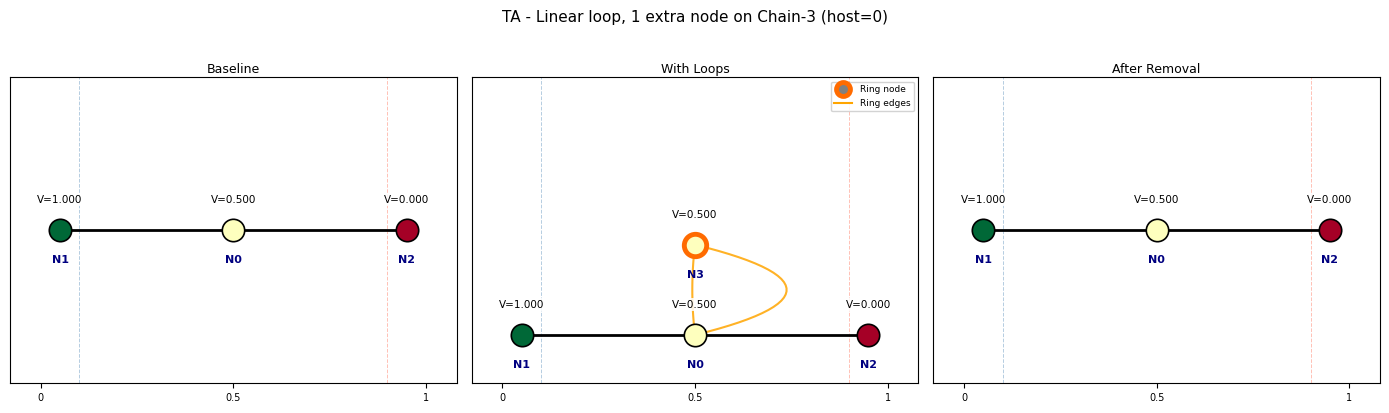

  TA  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  nodes 3->4 | Linear loop, 1 extra node on Chain-3 (host=0)


In [ ]:
run_and_report_node_loop_test(_cfg_by_id['A'])


**Test B** -- Linear loop, 2 extra nodes on Chain-3 (host=0)

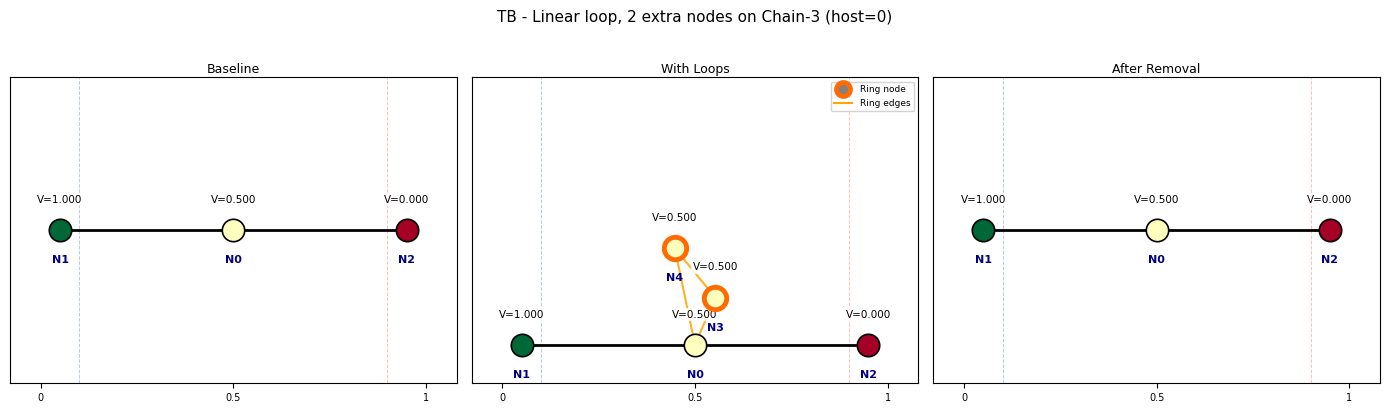

  TB  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  nodes 3->5 | Linear loop, 2 extra nodes on Chain-3 (host=0)


In [ ]:
run_and_report_node_loop_test(_cfg_by_id['B'])


**Test C** -- Linear loop, 3 extra nodes on Chain-3 (host=0)

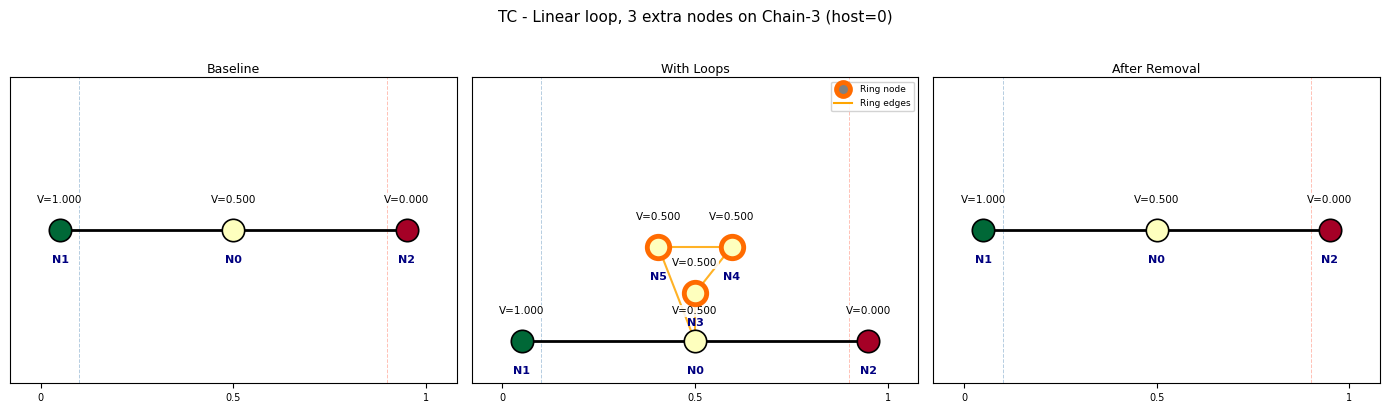

  TC  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  nodes 3->6 | Linear loop, 3 extra nodes on Chain-3 (host=0)


In [ ]:
run_and_report_node_loop_test(_cfg_by_id['C'])


**Test D** -- Branched loop, 3 ring + 1 branch on Chain-3 (host=0)

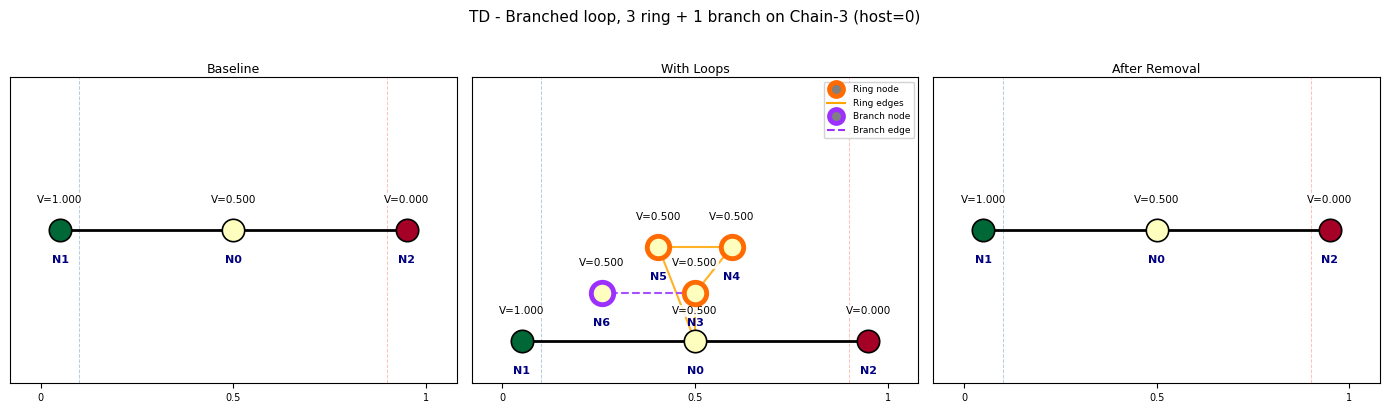

  TD  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  nodes 3->7 | Branched loop, 3 ring + 1 branch on Chain-3 (host=0)


In [ ]:
run_and_report_node_loop_test(_cfg_by_id['D'])


**Test E** -- Branched loop, 3 ring + 2 branches on Chain-5 (host=1)

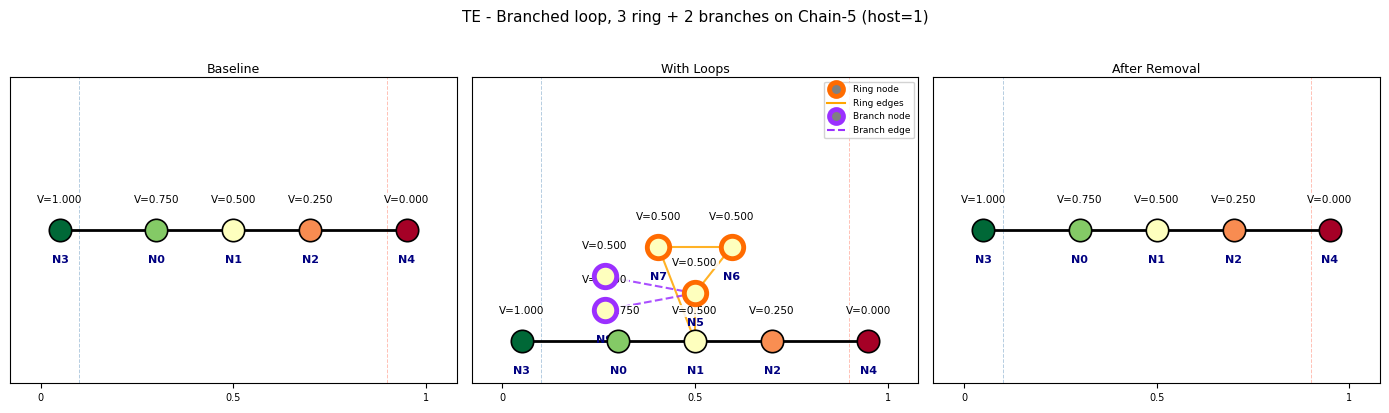

  TE  PASS  R  4000.00 ->  4000.00 ->  4000.00 Ohm (Delta-0.0%)  restored=OK  perc=OK  nodes 5->10 | Branched loop, 3 ring + 2 branches on Chain-5 (host=1)


In [ ]:
run_and_report_node_loop_test(_cfg_by_id['E'])


**Test F** -- Chorded loop, 4 ring + chord on Chain-5 (host=1)

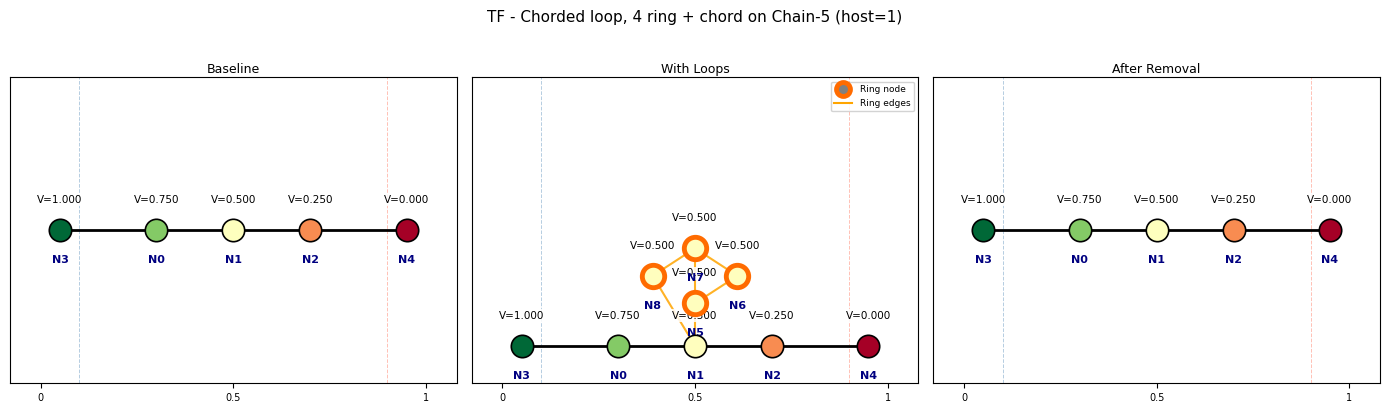

  TF  PASS  R  4000.00 ->  4000.00 ->  4000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  nodes 5->9 | Chorded loop, 4 ring + chord on Chain-5 (host=1)


In [ ]:
run_and_report_node_loop_test(_cfg_by_id['F'])


**Test G** -- Linear loop on SOURCE node (host=1 of Chain-3)

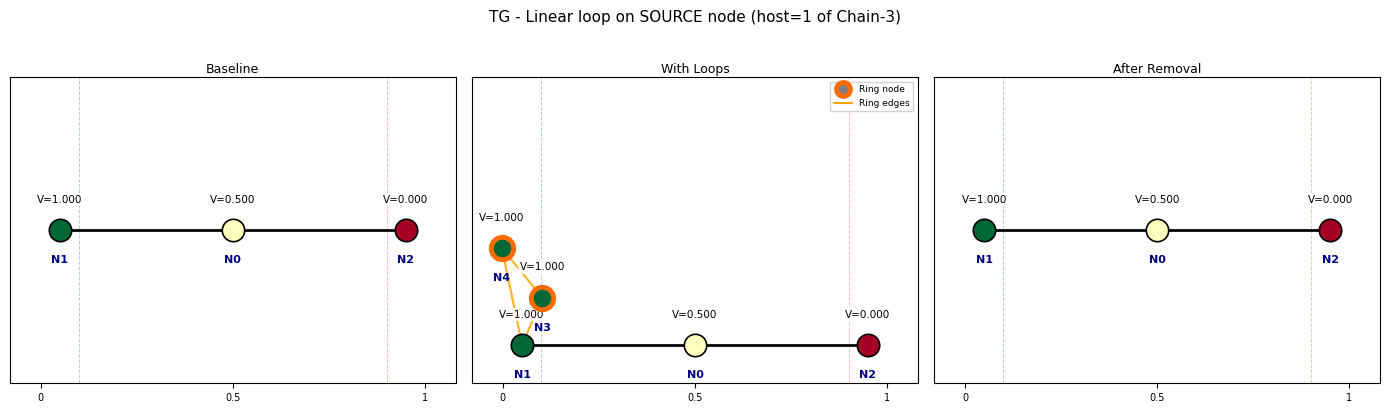

  TG  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  nodes 3->5 | Linear loop on SOURCE node (host=1 of Chain-3)


In [ ]:
run_and_report_node_loop_test(_cfg_by_id['G'])


---
## Test H — Two linear loops simultaneously on Chain-3 (hosts=0 and 2)


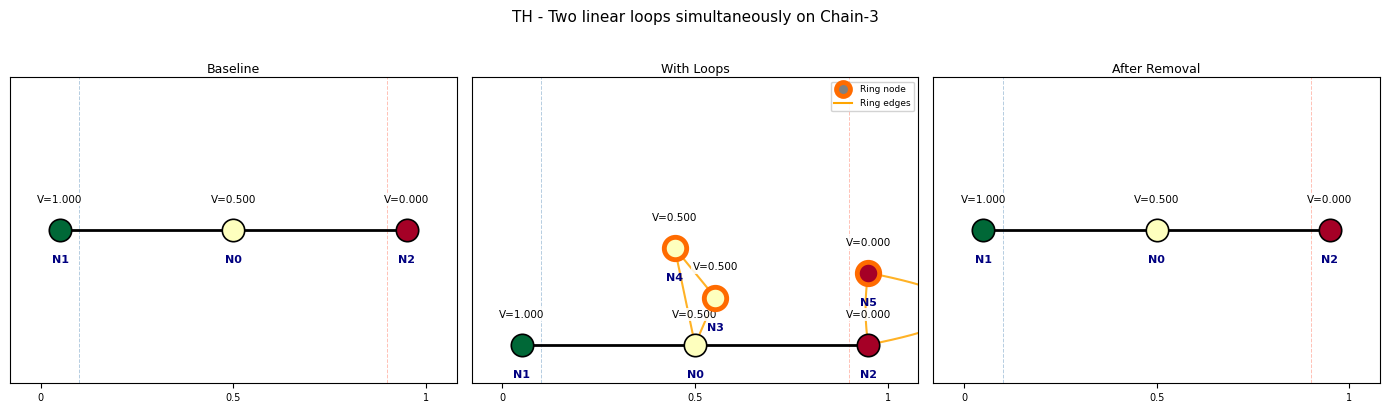

  TH  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  nodes 3->6 | Two linear loops simultaneously on Chain-3


In [ ]:
run_and_report_dual_loop_test(
    'H', 'Two linear loops simultaneously on Chain-3',
    intersections_t1, graph_t1, seg_t1, src_t1, drn_t1,
    loops=[dict(host_node=0, n_loop_nodes=2, topology='linear'),
           dict(host_node=2, n_loop_nodes=1, topology='linear')],
)


---
## Connected Self-Loops: Loops Attached to Other Loops (Tests I-L)


**Test I** -- Chained linear loops: loop 2 attached to a node of loop 1 (Chain-3, host=0)

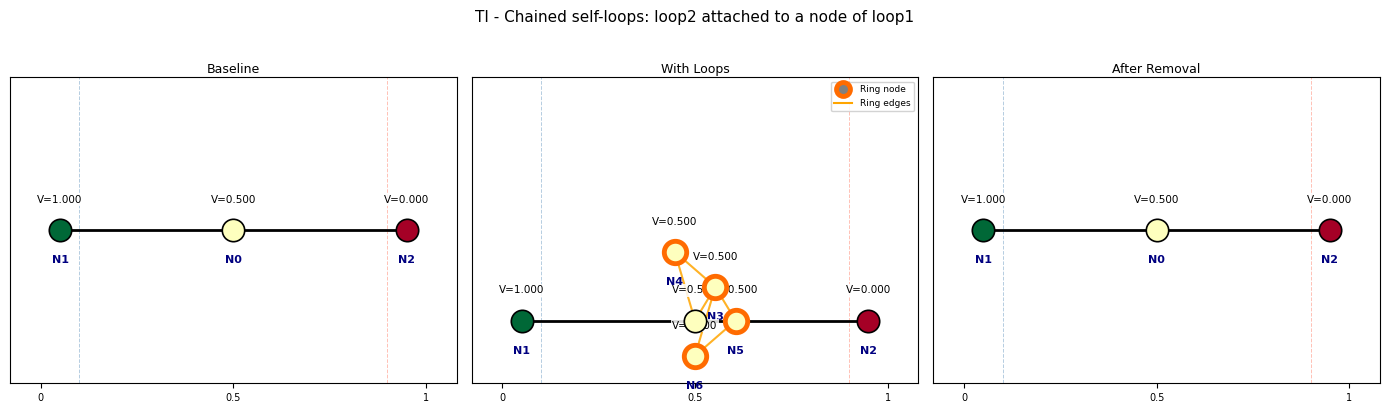

  TI  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta-0.0%)  restored=OK  perc=OK  nodes 3->7 | Chained self-loops: loop2 attached to a node of loop1


In [ ]:
run_and_report_dual_loop_test(
    'I', 'Chained self-loops: loop2 attached to a node of loop1',
    intersections_t1, graph_t1, seg_t1, src_t1, drn_t1,
    loops=[dict(host_node=0, n_loop_nodes=2, topology='linear'),
           # host_node=3 is a ring node created by the loop above --
           # this loop is attached to (i.e. "grows out of") that loop.
           dict(host_node=3, n_loop_nodes=2, topology='linear', direction=-1.0)],
)


**Test J** -- Three-level nested self-loop chain (loop of loop of loop) on Chain-5 (host=1)

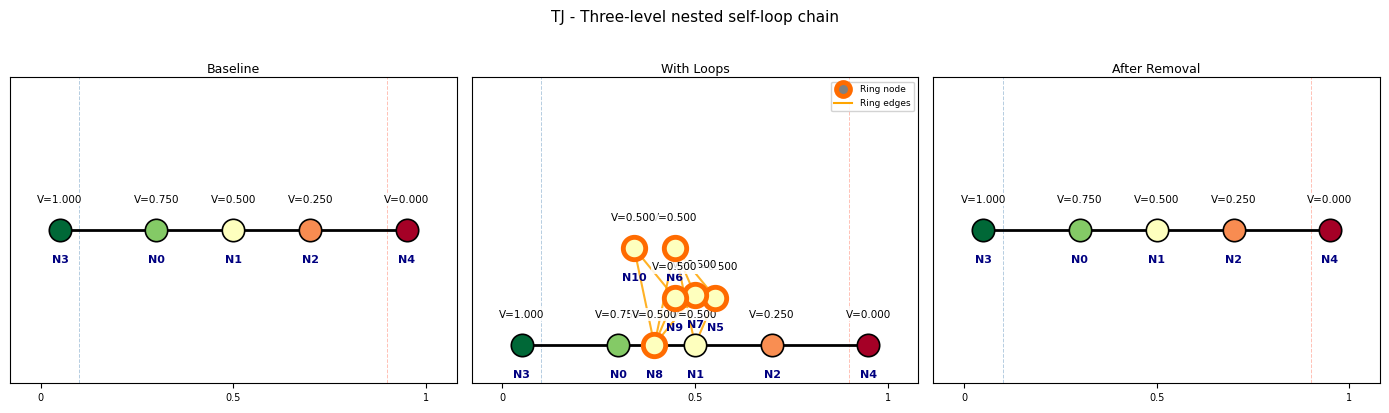

  TJ  PASS  R  4000.00 ->  4000.00 ->  4000.00 Ohm (Delta-0.0%)  restored=OK  perc=OK  nodes 5->11 | Three-level nested self-loop chain


In [ ]:
run_and_report_dual_loop_test(
    'J', 'Three-level nested self-loop chain',
    intersections_t7, graph_t7, seg_t7, src_t7, drn_t7,
    loops=[dict(host_node=1, n_loop_nodes=2, topology='linear'),
           # ring nodes of the previous loop are [5, 6]; attach loop 2 to node 6
           dict(host_node=6, n_loop_nodes=2, topology='linear', direction=-1.0),
           # ring nodes of loop 2 are [7, 8]; attach loop 3 to node 8
           dict(host_node=8, n_loop_nodes=2, topology='linear', direction=1.0)],
)


**Test K** -- Hub node: one loop-1 node hosts two further connected self-loops (star topology, Chain-3, host=0)

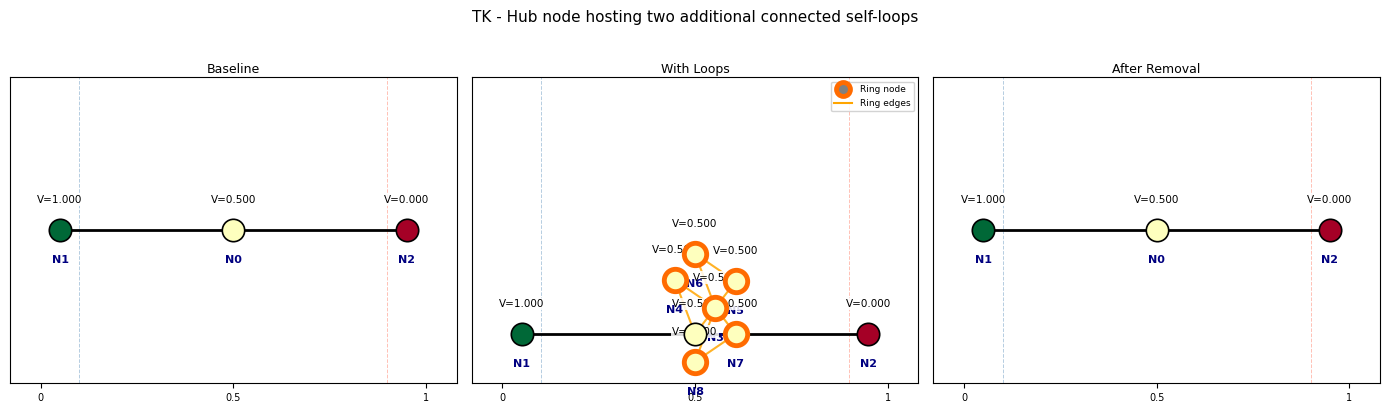

  TK  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  nodes 3->9 | Hub node hosting two additional connected self-loops


In [ ]:
run_and_report_dual_loop_test(
    'K', 'Hub node hosting two additional connected self-loops',
    intersections_t1, graph_t1, seg_t1, src_t1, drn_t1,
    loops=[dict(host_node=0, n_loop_nodes=2, topology='linear'),
           # both loops below attach to the SAME node (3) created by loop 1,
           # turning it into a hub shared by three connected self-loops
           dict(host_node=3, n_loop_nodes=2, topology='linear', direction=1.0),
           dict(host_node=3, n_loop_nodes=2, topology='linear', direction=-1.0)],
)


**Test L** -- Branched self-loop attached to a linear self-loop's node (mixed topology chain, Chain-5, host=1)

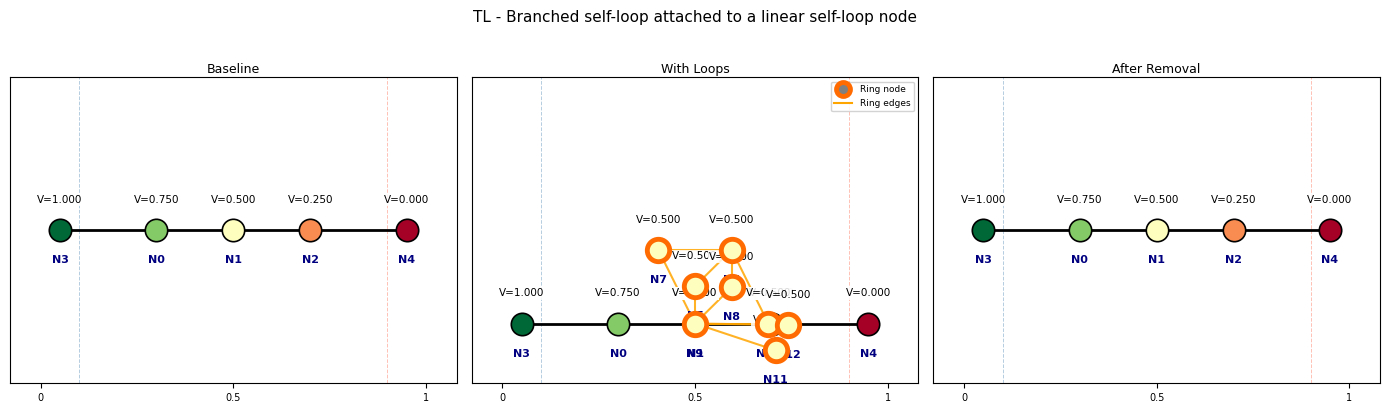

  TL  PASS  R  4000.00 ->  4000.00 ->  4000.00 Ohm (Delta-0.0%)  restored=OK  perc=OK  nodes 5->13 | Branched self-loop attached to a linear self-loop node


In [ ]:
run_and_report_dual_loop_test(
    'L', 'Branched self-loop attached to a linear self-loop node',
    intersections_t7, graph_t7, seg_t7, src_t7, drn_t7,
    loops=[dict(host_node=1, n_loop_nodes=3, topology='linear'),
           # ring nodes of loop 1 are [5, 6, 7]; attach a branched loop to node 6
           dict(host_node=6, n_loop_nodes=3, topology='branched',
                n_branch_nodes=2, branch_from=1, direction=-1.0)],
)


---
## Admittance-Matrix Invertibility Tests (Tests M-Q)


In [ ]:
from admittance_checks import run_and_report_admittance_test

### New Test Matrix (Tests M-Q)

Same data-driven style as `TEST_CONFIGS` above: one dict per test, only
the parameters that differ. `run_and_report_admittance_test` handles run,
assert (impedance + connectivity + admittance invertibility), persist,
and plot.

In [ ]:
NEW_TEST_CONFIGS = [
    dict(id='M', label='Linear loop, 4 extra nodes on Chain-3 (host=0)',
         net=(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1),
         host_node=0, n_loop_nodes=4, topology='linear'),
    dict(id='N', label='Branched loop, 3 ring + 3 branches on Chain-5 (host=1)',
         net=(intersections_t7, graph_t7, seg_t7, src_t7, drn_t7),
         host_node=1, n_loop_nodes=3, topology='branched',
         n_branch_nodes=3, branch_from=1),
    dict(id='O', label='Chorded loop, 5 ring + chord on Chain-5 (host=1)',
         net=(intersections_t7, graph_t7, seg_t7, src_t7, drn_t7),
         host_node=1, n_loop_nodes=5, topology='chorded', chord_pair=(0, 3)),
    dict(id='P', label='Linear loop on SOURCE node, 3 extra nodes (Chain-3, host=1)',
         net=(intersections_t1, graph_t1, seg_t1, src_t1, drn_t1),
         host_node=1, n_loop_nodes=3, topology='linear'),
    dict(id='Q', label='Linear loop on DRAIN node, 2 extra nodes (Chain-5, host=4)',
         net=(intersections_t7, graph_t7, seg_t7, src_t7, drn_t7),
         host_node=4, n_loop_nodes=2, topology='linear'),
]

# Quick lookup so each test cell below can just grab its own config
_cfg_by_id_adm = {c["id"]: c for c in NEW_TEST_CONFIGS}

### Execute Tests M-Q

Each test call also prints one extra line reporting the reduced
admittance matrix's size, condition number, whether it was flagged
singular, whether `np.linalg.inv` actually succeeded, and the max
voltage discrepancy between the manual `M^-1` solve and
`ImpedanceCalculator`'s own solution.

**Test M** -- Linear loop, 4 extra nodes on Chain-3 (host=0)

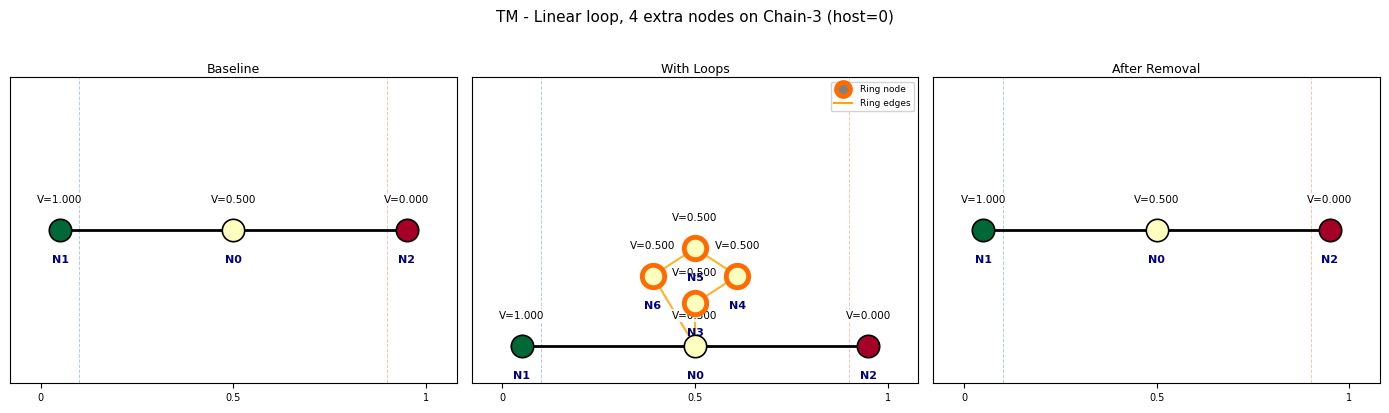

  TM  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta-0.0%)  restored=OK  perc=OK  | Linear loop, 4 extra nodes on Chain-3 (host=0)
      admittance (cleaned): 1x1 internal, cond(M)=1.000e+00, singular=no, invertible=YES, |ΔV| vs solve=0.00e+00


In [ ]:
run_and_report_admittance_test(_cfg_by_id_adm['M'], k=k_test)

**Test N** -- Branched loop, 3 ring + 3 branches on Chain-5 (host=1)

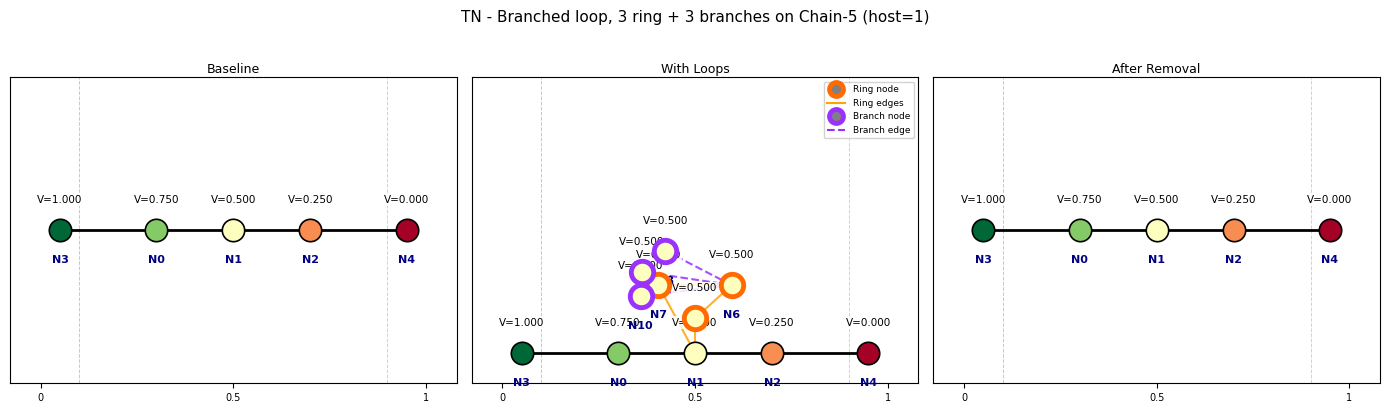

  TN  PASS  R  4000.00 ->  4000.00 ->  4000.00 Ohm (Delta-0.0%)  restored=OK  perc=OK  | Branched loop, 3 ring + 3 branches on Chain-5 (host=1)
      admittance (cleaned): 3x3 internal, cond(M)=5.828e+00, singular=no, invertible=YES, |ΔV| vs solve=2.78e-17


In [ ]:
run_and_report_admittance_test(_cfg_by_id_adm['N'], k=k_test)

**Test O** -- Chorded loop, 5 ring + chord on Chain-5 (host=1)

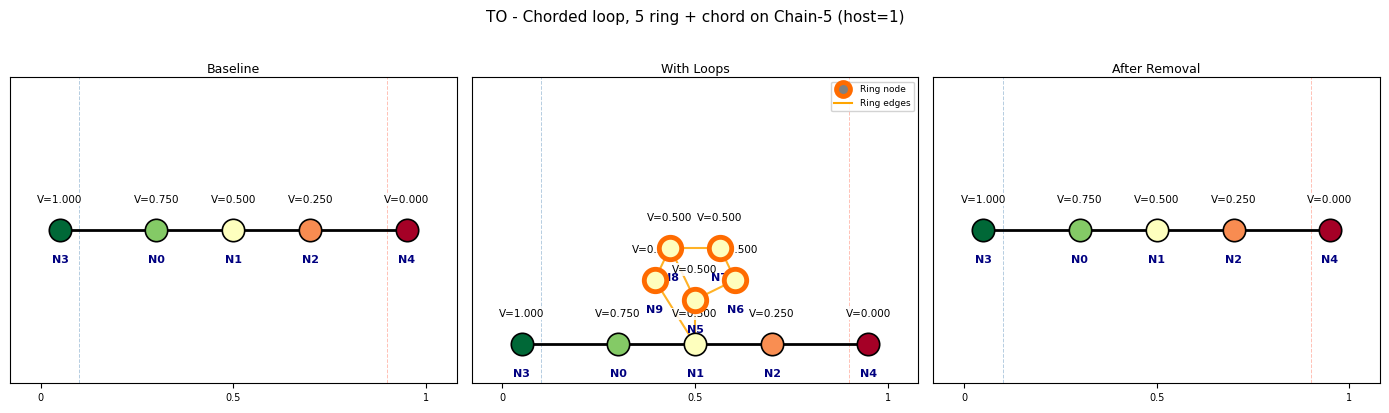

  TO  PASS  R  4000.00 ->  4000.00 ->  4000.00 Ohm (Delta-0.0%)  restored=OK  perc=OK  | Chorded loop, 5 ring + chord on Chain-5 (host=1)
      admittance (cleaned): 3x3 internal, cond(M)=5.828e+00, singular=no, invertible=YES, |ΔV| vs solve=2.78e-17


In [ ]:
run_and_report_admittance_test(_cfg_by_id_adm['O'], k=k_test)

**Test P** -- Linear loop on SOURCE node, 3 extra nodes (Chain-3, host=1)

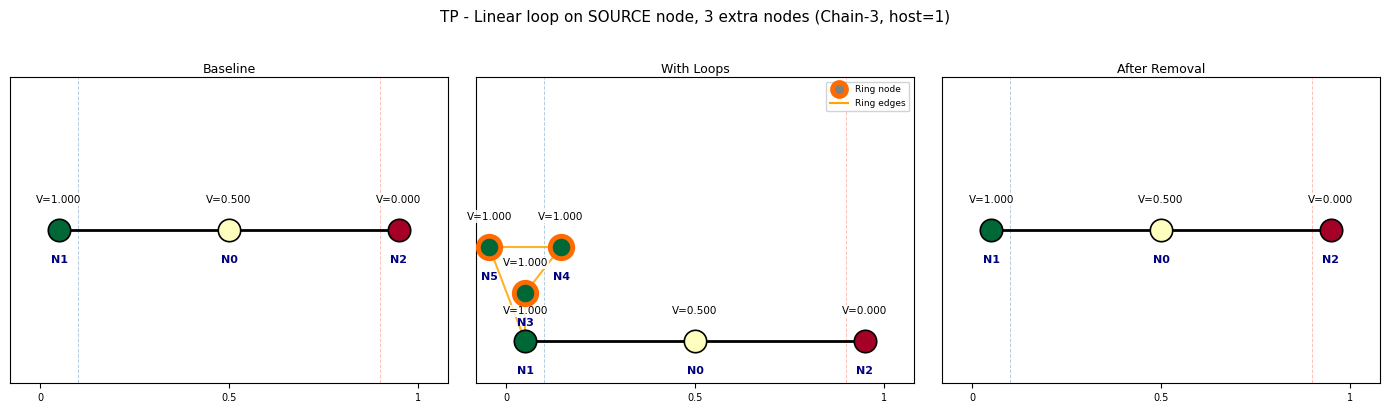

  TP  PASS  R  2000.00 ->  2000.00 ->  2000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  | Linear loop on SOURCE node, 3 extra nodes (Chain-3, host=1)
      admittance (cleaned): 1x1 internal, cond(M)=1.000e+00, singular=no, invertible=YES, |ΔV| vs solve=0.00e+00


In [ ]:
run_and_report_admittance_test(_cfg_by_id_adm['P'], k=k_test)

**Test Q** -- Linear loop on DRAIN node, 2 extra nodes (Chain-5, host=4)

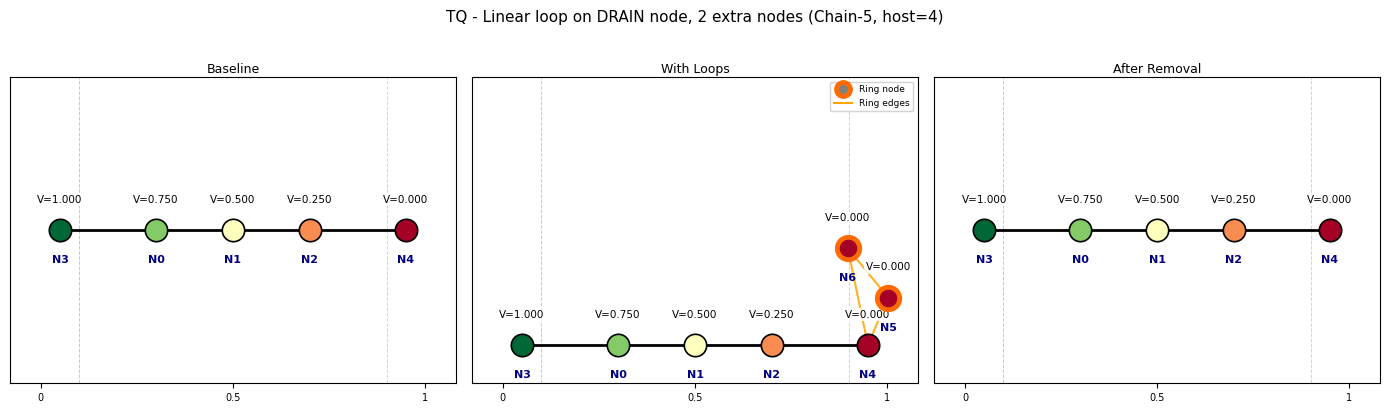

  TQ  PASS  R  4000.00 ->  4000.00 ->  4000.00 Ohm (Delta+0.0%)  restored=OK  perc=OK  | Linear loop on DRAIN node, 2 extra nodes (Chain-5, host=4)
      admittance (cleaned): 3x3 internal, cond(M)=5.828e+00, singular=no, invertible=YES, |ΔV| vs solve=2.78e-17


In [ ]:
run_and_report_admittance_test(_cfg_by_id_adm['Q'], k=k_test)

---
## In a nutshell: Tests M-Q

All five tests above confirm, for a variety of loop topologies (linear,
branched, chorded) attached at different hosts (internal, source, drain
nodes) on both test networks (Chain-3 and Chain-5): after the injected
node-loop is removed, the reduced admittance matrix `M` is **not
singular**, `np.linalg.inv(M)` succeeds, and the voltages obtained from
that explicit inversion match `ImpedanceCalculator`'s own solution to
within `1e-8` , i.e. the network is left in a state where node voltages
can genuinely be computed by inverting the admittance matrix, exactly as
before the loop was ever injected.